# Does fear predict the bounce? End-to-end pipeline

**Question.** After SPY has fallen, does the VIX term structure (VIX / VIX3M) help tell a recovery from a continuation, and does that make a better SPY-vs-BIL timing strategy after costs?

**Timing for the main one-day strategy.** We decide after the close on day *t* (VIX data is final at 16:15), trade at the close of *t+1*, and earn close *t+1* → close *t+2*.

This notebook walks through the whole project from the committed data snapshot, one call per team member. No market data is downloaded by default (pass `download=True` to `build_data` to refetch). The model penalties use completed 2017–2018 validation outcomes, and those penalties stay fixed during 2019–2025 evaluation. Earlier feature research examined evaluation outcomes, so this is **not an untouched research holdout**. The classifier and ten-day extensions were designed after seeing the original results and remain exploratory.

| Step | Member | Call |
|---|---|---|
| 1 | Sai | `member1.build_data()` |
| 2 | Luwei Chen | `member2.extract_features()` |
| 3 | Navneet Melarkode | `member3.train_models()` |
| 4 | Hieu Hoang | `member4.run_backtest()` |

The data, features and forecasts are a frozen, hash-checked snapshot. Steps 2 and 3 therefore **recompute** their stage and check row/column coverage and agreement **within numerical tolerance**, without overwriting the committed files. Step 3 reruns only the one-day ridge experiment; extension results are read from saved reports.

With no local raw CSVs, Step 1 loads the clean snapshot and saved checks. If raw CSVs are already present, it rebuilds the data reports. Step 4 regenerates `reports/backtest/` and `reports/analysis/`, so Run All can modify report files; do not commit those incidental changes.


In [1]:
import os, sys
from pathlib import Path

# Run from the repository root wherever the notebook is opened.
root = Path.cwd()
while not (root / "src").is_dir():
    if root == root.parent:
        raise RuntimeError("Open this notebook from inside the project folder.")
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root))

import pandas as pd
from IPython.display import Image, Markdown, display
from src.walkthrough import member1, member2, member3, member4, show
pd.set_option("display.width", 160, "display.max_columns", 30)
print("repository:", root)
print("python:", sys.executable, "| pandas", pd.__version__)
# The frozen snapshot was built with the versions in requirements.txt; other versions
# (e.g. pandas 3) change the last digits and the snapshot checks below will fail.
pins = dict(l.strip().split("==") for l in open("requirements.txt") if "==" in l)
assert pd.__version__ == pins["pandas"], f"pick the kernel with the pinned packages (pandas {pins['pandas']})"


repository: /private/tmp/dsa5205-notebook-fix-kafp70_y/project
python: /Users/navneetmelarkode/Documents/Projects/dsa5205/dsa5205-vol-timing/.venv/bin/python | pandas 2.3.3


## 1 · Data (Sai)

**Questions behind it**
- Which returns are we comparing? SPY and BIL *total* returns, with dividends, from close to close.
- How do we know the data is clean? 33 automatic checks cover trading calendars, missing values, VIX timing and return reconciliation.
- What must any strategy beat? Buy-and-hold SPY, BIL, and a static 50/50 SPY/BIL mix.

In [2]:
checks = member1.build_data()
checks["status"].value_counts()

No raw CSVs in /private/tmp/dsa5205-notebook-fix-kafp70_y/project/data/raw; using the committed panel (3530 rows, 2012-01-03 to 2026-01-15) and the saved checks. Pass download=True to rebuild from source.


status
PASS    33
Name: count, dtype: int64

,Unnamed: 0,ann_return,ann_vol,sharpe,max_dd,n_days
0,spy_bh,0.134592,0.173351,0.71908,-0.336998,3018.0
1,bil_bh,0.016820,0.002652,NaN,-0.002403,3018.0
2,mix_50,0.078159,0.086676,0.71908,-0.178535,3018.0


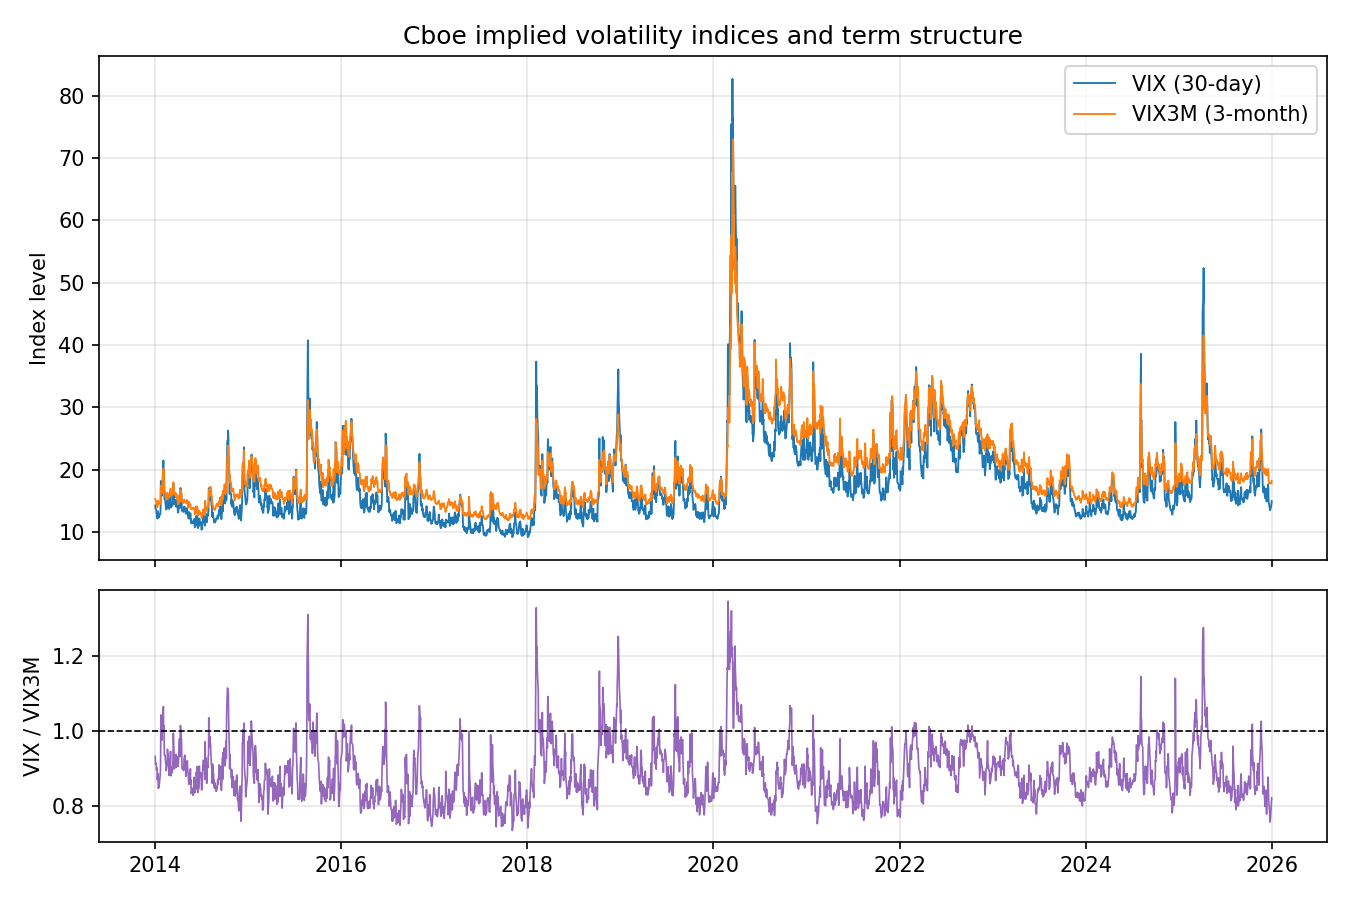

In [3]:
display(pd.read_csv("reports/data/benchmark_metrics.csv"))
display(Image("reports/data/fig_vix_term_structure.png", width=800))

### The code: total returns and the timing of the label

**What to say**
- Total return adds the dividend back on the ex-date: R_t = (P_t + D_t) / P_{t−1} − 1.
- `vix_ratio` uses only closes known at day *t*. Cboe's 16:15 close is final before we decide.
- The label `fwd_spy_xs` is shifted by **2** days. Deciding at *t* and trading at close *t+1* earns the return dated *t+2*. This is where look-ahead could creep in, and it doesn't.

In [4]:
from src.data import build
show(build.etf_returns, "p, d, o", "pr =")
show(build.build, "Signal-side helper", "fwd_spy_xs")

`src/data/build.py`, lines 45-47
```python
p, d, o = df["Close"], df["Dividends"].fillna(0.0), df["Open"]
tr = (p + d) / p.shift(1) - 1
pr = p / p.shift(1) - 1
```

`src/data/build.py`, lines 101-110
```python
# Signal-side helper already known at the decision time t (16:15 ET close).
panel["vix_ratio"] = panel["vix_close"] / panel["vix3m_close"]   # >1 = backwardation

# ---------------------------------------------------------------- forward returns
# Decision at close t, executed at close t+1, held to close t+2.
# The return on that holding is the close-to-close return dated t+2.
k = 2
panel["fwd_spy_tr"] = panel["spy_tr_cc"].shift(-k)
panel["fwd_bil_tr"] = panel["bil_tr_cc"].shift(-k)
panel["fwd_spy_xs"] = panel["fwd_spy_tr"] - panel["fwd_bil_tr"]
```

## 2 · Features and decline events (Luwei Chen)

**Questions behind it**
- What does a feature on day *t* know? Only data dated *t* or earlier. Leakage tests check this.
- What is a "decline"? A drawdown trigger. It is labelled **recovery**, **continuation** or **unresolved** using up/down barriers over the next 10 days.
- Which features carry the hypothesis? `ts_ratio` (VIX/VIX3M) and its interactions with decline state (`x_cond_ts`, `x_mom_ts`). Earlier exploratory work also examined evaluation outcomes; see the research-history disclosure above. The subsequent model-penalty selection uses completed design-period outcomes only.

In [5]:
features = member2.extract_features()
import json
sets = json.load(open("data/processed/feature_sets.json"))
display(pd.Series({k: len(v) for k, v in sets.items()}, name="n_features"))
features.tail()

Recomputing from the panel:
  features      3018 rows x 14 cols   max gap 0.0e+00   matches committed snapshot within absolute tolerance 1.0e-08
  targets       3530 rows x  3 cols   max gap 0.0e+00   matches committed snapshot within absolute tolerance 1.0e-08
  events        3530 rows x  6 cols   max gap 0.0e+00   matches committed snapshot within absolute tolerance 1.0e-08


base     5
vix     11
full    14
Name: n_features, dtype: int64

,dec_dd,dec_mom,dec_vol,dec_cond,ma200_gap,vix_log,vix_z,vix_chg5,ts_ratio,ts_backw,vrp,x_cond_ts,x_mom_backw,x_mom_ts
date,,,,,,,,,,,,,,
2025-12-24,0.000000,2.487101,0.005625,0.0,0.111947,2.600465,-1.039447,-0.268570,0.758019,0.0,0.045412,-0.0,0.0,-0.601831
2025-12-26,-0.000101,1.916120,0.005473,0.0,0.110601,2.610070,-1.010753,-0.215467,0.765335,0.0,0.049126,-0.0,0.0,-0.449647
2025-12-29,-0.003665,0.874999,0.005452,0.0,0.105373,2.653242,-0.897395,-0.048790,0.796857,0.0,0.055452,-0.0,0.0,-0.177749
2025-12-30,-0.004881,0.266639,0.005339,0.0,0.102865,2.662355,-0.872338,0.017600,0.806415,0.0,0.058545,-0.0,0.0,-0.051617
2025-12-31,-0.012254,-0.698198,0.005624,0.0,0.093629,2.704711,-0.754211,0.065654,0.822332,0.0,0.060228,-0.0,-0.0,0.124047


### The code: decline state, VIX features, recovery labels

**What to say**
- A **decline** = at least a 2% drawdown from the **20-day high**, **and** a five-day return at most −1 times the 20-day daily volatility multiplied by √5.
- `ts_ratio` = VIX / VIX3M. Above 1 means backwardation: short-term fear exceeds longer-term fear.
- The label follows SPY for 10 days after the trigger. Hitting the upper barrier first means **recovery**, the lower barrier first means **continuation**, neither means **unresolved**. The barrier width scales with volatility.
- The path starts at `i + 1` (the execution day), not at the decision day.

In [6]:
from src.features import events, feature_build
show(events.decline_signals)
show(feature_build.vix_features)
show(events.build)
show(events.barrier_labels)

`src/features/events.py`, lines 46-53
```python
def decline_signals(panel: pd.DataFrame) -> pd.DataFrame:
    a = panel["spy_adj_close"]
    vol = panel["spy_tr_cc"].rolling(VOL_WINDOW).std() # find the rolling volatility in past 20 days
    return pd.DataFrame({
        "dec_dd": a / a.rolling(DD_LOOKBACK).max() - 1,
        "dec_mom": (a / a.shift(MOM_DAYS) - 1) / (vol * np.sqrt(MOM_DAYS)),
        "dec_vol": vol,
    })
```

`src/features/feature_build.py`, lines 59-68
```python
def vix_features(panel: pd.DataFrame) -> pd.DataFrame:
    vix, ratio = panel["vix_close"], panel["vix_ratio"]
    return pd.DataFrame({
        "vix_log": np.log(vix),
        "vix_z": (vix - vix.rolling(252).mean()) / vix.rolling(252).std(),
        "vix_chg5": np.log(vix / vix.shift(5)),
        "ts_ratio": ratio,
        "ts_backw": (ratio > 1).astype(float),
        "ts_chg5": ratio - ratio.shift(5),
    })
```

`src/features/events.py`, lines 87-93
```python
def build(panel: pd.DataFrame, s: float = S, p: float = P, h: int = H, k: float = K) -> pd.DataFrame:
    sig = decline_signals(panel) # this creates the dec_dd, dec_mom, and dec_vol columns
    sig["dec_cond"] = (sig["dec_dd"] <= -s) & (sig["dec_mom"] <= -p) # boolean series
    sig["ev_start"] = event_starts(sig["dec_cond"], h) # clears out overlapping events to get separete ones
    sig["ev_barrier"] = (k * sig["dec_vol"] * np.sqrt(h)).where(sig["ev_start"])
    ev = sig[["dec_cond", "ev_start", "ev_barrier"]]   # dec_dd/mom/vol live in the features file
    return ev.join(barrier_labels(panel, sig["ev_start"], sig["ev_barrier"], h))
```

`src/features/events.py`, lines 67-84
```python
def barrier_labels(panel: pd.DataFrame, starts: pd.Series, width: pd.Series, h: int) -> pd.DataFrame:
    spy = panel["spy_adj_close"].to_numpy()
    n = len(spy)
    cols = {c: np.full(n, np.nan) for c in ["fwd_ev_label", "fwd_ev_label_bin", "fwd_ev_days"]}
    for i in np.flatnonzero(starts.to_numpy()):
        if i + 1 + h >= n:                      # window runs past the end of the data
            continue
        w = width.iloc[i]
        path = spy[i + 2:i + 2 + h] / spy[i + 1] - 1
        up = np.flatnonzero(path >= w)
        dn = np.flatnonzero(path <= -w)
        j_up = up[0] if len(up) else h # find the first day the path crosses the upper barrier
        j_dn = dn[0] if len(dn) else h
        label, j = (1, j_up) if j_up < j_dn else (-1, j_dn) if j_dn < j_up else (0, h - 1)
        cols["fwd_ev_label"][i] = label
        cols["fwd_ev_label_bin"][i] = label if label != 0 else (1 if path[-1] > 0 else -1)
        cols["fwd_ev_days"][i] = j + 1
    return pd.DataFrame(cols, index=panel.index)
```

## 3 · Models (Navneet Melarkode)

**Questions behind it**
- What is predicted? The one-day SPY-minus-BIL total return earned from close *t+1* to close *t+2*, after deciding on day *t*.
- Why ridge? L2 regularisation shrinks coefficients when related predictors carry overlapping information. Each refit uses exactly **756 matured training observations**.
- How is it validated? Choose α on completed **2017–2018** validation outcomes, then hold it fixed during **2019–2025** evaluation. Coefficients and the scaler are refitted daily. All original sets selected α = 1,000, the grid's upper boundary, not proof of a global optimum.
- How is term structure isolated? Compare **base → VIX level → term structure → interactions**, with a rolling historical-mean baseline. `ridge_vix_matched` adds term structure while retaining the VIX-level model's α.

This section recomputes the original one-day ridge experiment in memory, including its unchanged design-period selection, and compares forecasts with the saved snapshot. The later classifier and ten-day extensions are **exploratory**. This notebook displays the saved classifier results without refitting; the ten-day ridge extension is documented separately. Earlier feature research saw evaluation outcomes, so no untouched-holdout claim is made.


### The code: the walk-forward loop

**What to say**
- For every decision date the ridge coefficients are refitted from scratch.
- `stop` admits only labels realised by that day's close. With next-close execution, a one-day training label becomes available at *s+2*; the decision is after 16:15 ET.
- The training window contains exactly the latest **756 matured observations**. Clipping and scaling are fitted on that window only.
- In the evaluation pass, α stays fixed at its design-selected value. Earlier evaluation labels can enter later training windows once they mature. Fixed α does not mean fixed coefficients.


In [7]:
from src.models import walk_forward
show(walk_forward.walk_forward, "for date in dates", "prediction = float")

`src/models/walk_forward.py`, lines 133-172
```python
for date in dates:
    # Side=right permits labels realised at today's close: the decision is later.
    stop = int(np.searchsorted(label_dates, date.to_datetime64(), side="right"))
    timing = data.calendar.loc[date]
    status = "predicted"
    if pd.isna(timing.label_end_date):
        status = "incomplete_outcome_calendar"
    elif outcome_cutoff is not None and timing.label_end_date > outcome_cutoff:
        status = "outcome_after_design_end"
    elif stop < train_window:
        status = "insufficient_history"
    coverage.append({"decision_date": date, "label_end_date": timing.label_end_date,
                     "available_train_rows": stop, "status": status})
    if status != "predicted":
        continue

    start = stop - train_window
    X = data.features.iloc[start:stop]
    y = data.target.iloc[start:stop].to_numpy(dtype=float)
    if not np.isfinite(y).all():
        raise ValueError(f"nonfinite training label at decision {date.date()}")
    # Scaling is columnwise, so one full-set scaler equals a separate fit for
    # each subset. It is fitted anew on ONLY the matured training window.
    scaler = PastScaler().fit(X)
    Xz = scaler.transform(X).to_numpy()
    xz = scaler.transform(data.features.loc[[date]]).to_numpy()
    audit = {"decision_date": date, "execution_date": timing.execution_date,
             "label_end_date": timing.label_end_date, "horizon": data.horizon,
             "n_train": train_window, "train_start_date": X.index[0],
             "train_end_date": X.index[-1],
             "train_last_label_end_date": pd.Timestamp(label_dates[stop - 1]),
             "decline": int(data.features.at[date, "dec_cond"])}
    predictions.append({**audit, "model_id": "historical_mean", "feature_set": "none",
                        "alpha": np.nan, "prediction": float(y.mean())})
    for model_id, (feature_set, alphas) in models.items():
        cols = column_positions[feature_set]
        for alpha in alphas:
            model = Ridge(alpha=float(alpha), fit_intercept=True, solver="cholesky")
            model.fit(Xz[:, cols], y)
            prediction = float(model.predict(xz[:, cols])[0])
```

### Run + results: one-day ridge

The first table contains six forecast series: five ridge variants and the rolling-mean baseline. **`oos_r2_pct` is a percentage reduction in squared forecast error relative to the rolling mean**, not a trading return. Positive is better. The second table isolates the term-structure contribution while holding α fixed.

**What to say**
- The rerun checks the same unique dates and columns, then numerical agreement within the printed absolute tolerance. It does not overwrite the saved signals.
- Full ridge reduces squared error by about **0.228%** versus the rolling mean.
- Adding term structure alone reduces MSE by only **0.00556% overall** and **0.354% on decline days**. These are descriptive changes, not established trading gains.


In [8]:
model_metrics = member3.train_models()
pooled = model_metrics.query("decision_year == 'all' and segment == 'all'")
display(
    pooled.assign(oos_r2_pct=100 * pooled.oos_r2)
    [["model_id", "n", "oos_r2_pct"]].round(6)
)

# Saved comparison from the same frozen experiment; negative change means lower MSE.
comparisons = pd.read_csv("reports/models/feature_comparisons.csv")
term_only = comparisons.query(
    "comparison == 'term_structure_same_alpha' and segment in ['all', 'decline']"
)
display(Markdown("**Adding term structure at the same α:** `ridge_vix_matched` versus `ridge_vix_level`. Negative MSE change favours adding term structure."))
display(term_only[["segment", "n", "mse_change_pct"]].round(6))


Recomputing one-day ridge validation and forecasts (five ridge models + rolling-mean baseline)...


Design-selected alphas (held fixed during evaluation): {'base': 1000.0, 'vix_level': 1000.0, 'vix': 1000.0, 'full': 1000.0}
  forecasts     1760 rows x  9 cols   max gap 0.0e+00   matches committed snapshot within absolute tolerance 1.0e-10


,model_id,n,oos_r2_pct
0,historical_mean,1760,0.000000
24,ridge_base,1760,-0.177635
48,ridge_full,1760,0.228137
72,ridge_vix,1760,-0.176195
96,ridge_vix_level,1760,-0.181768
120,ridge_vix_matched,1760,-0.176195


**Adding term structure at the same α:** `ridge_vix_matched` versus `ridge_vix_level`. Negative MSE change favours adding term structure.

,segment,n,mse_change_pct
6,all,1760,-0.005562
7,decline,175,-0.353716


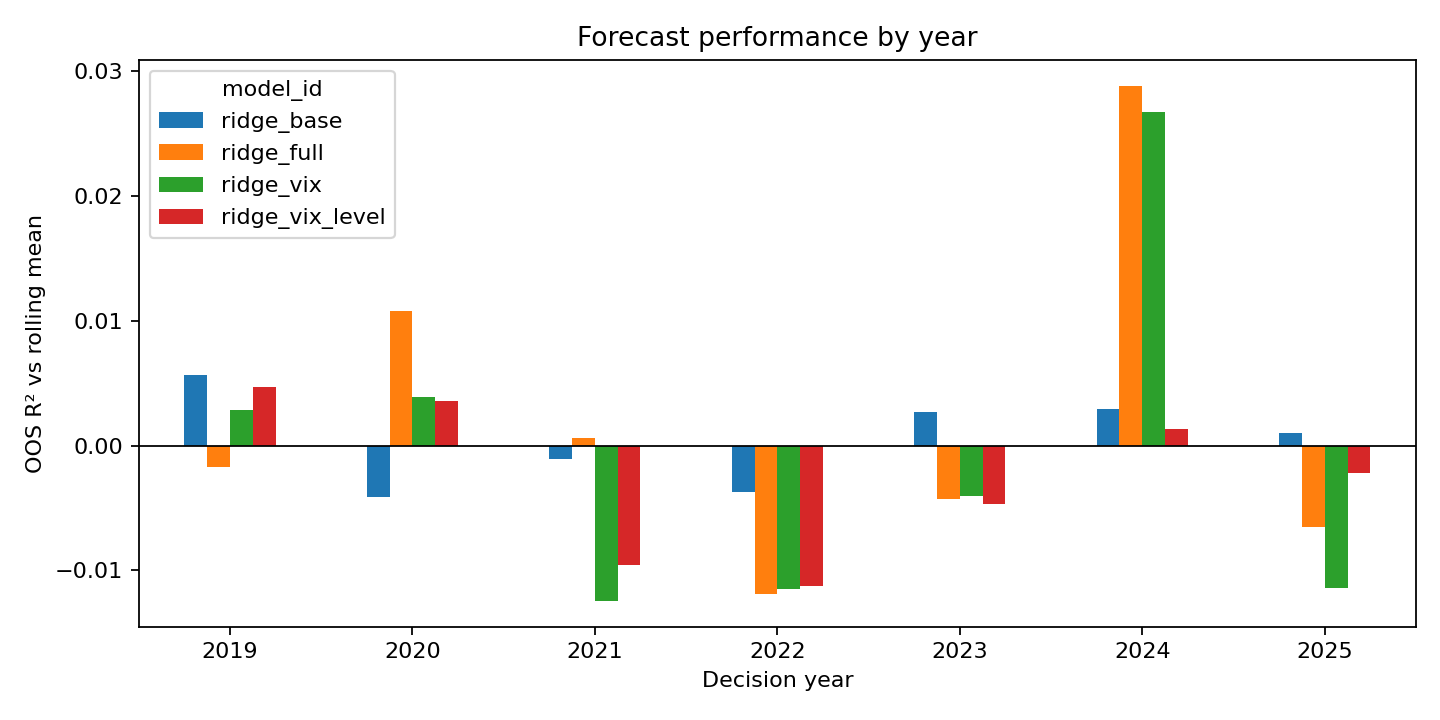

In [9]:
display(Image("reports/models/yearly_oos_r2.png", width=800))


### Exploratory extension: saved recovery-classifier results

This three-class logistic classifier directly estimates **recovery, continuation and unresolved** probabilities over the ten-session barrier horizon. The table below loads frozen reports; it does **not** train the classifier or the ten-day ridge extension.

**What to say**
- There are **175 trigger dates across 53 represented episodes**, not 175 independent events. Evaluation gives each episode equal total weight.
- Compare with the training-only historical class prior using **three-class log loss**, where lower is better.
- The term-structure model's loss is **1.017874 versus 0.977701**, or **4.109% higher**. Its absolute loss difference is **+0.040173**, with an approximate 95% episode-block interval **[−0.027368, +0.118418]**. The interval crosses zero; no improvement is established.
- **`change_pct` is a percentage; `delta_log_loss` and both interval bounds are absolute log-loss units.** The AUC is recovery **versus both continuation and unresolved combined**.

The matched-C classifier is identical to the ordinary term-structure classifier in this snapshot; it is not independent confirmation. Further class-calibration and stability diagnostics are in `reports/recovery_diagnostics/report.md`.


In [10]:
# Read saved evaluations only; no fitting, calibration or penalty selection here.
classifier_metrics = pd.read_csv("reports/recovery_evaluation/metrics.csv")
classifier_pooled = classifier_metrics.query(
    "period == 'evaluation' and subset == 'all_triggers' "
    "and decision_year == 'all' and weighting == 'episode'"
)
display(classifier_pooled[["model_id", "log_loss", "recovery_vs_rest_auc"]].round(6))

paired = pd.read_csv("reports/recovery_evaluation/paired_loss_intervals.csv")
loss_vs_prior = paired.loc[paired.comparator == "class_prior", [
    "model_id", "loss_difference", "loss_change_pct", "ci95_lower", "ci95_upper"
]].rename(columns={
    "loss_difference": "delta_log_loss",
    "loss_change_pct": "change_pct",
    "ci95_lower": "ci95_low_log_loss",
    "ci95_upper": "ci95_high_log_loss",
})
display(loss_vs_prior.round(6))


,model_id,log_loss,recovery_vs_rest_auc
12,class_prior,0.977701,0.444247
44,logit_price,0.996040,0.564427
76,logit_term_structure,1.017874,0.519818
108,logit_term_structure_matched,1.017874,0.519818
140,logit_vix_level,1.017425,0.500020
172,uniform,1.098612,0.500000


,model_id,delta_log_loss,change_pct,ci95_low_log_loss,ci95_high_log_loss
0,logit_price,0.018339,1.875711,-0.030253,0.066398
2,logit_vix_level,0.039724,4.062992,-0.025427,0.118645
4,logit_term_structure,0.040173,4.108889,-0.027368,0.118418
6,logit_term_structure_matched,0.040173,4.108889,-0.027368,0.118418


## 4 · Backtest and evaluation (Hieu Hoang)

**Questions behind it**
- How does a forecast become a position? Three allocation rules, all frozen in advance:
  - `sign`, the **primary** rule: hold SPY if the forecast is above 0, otherwise BIL.
  - `mv`: mean-variance sizing with γ = 5.
  - `decline_overlay`: step out of SPY only during declines.
- What are the costs? 5 bps per unit traded, counting drift, starting from cash. We also test 0–20 bps.
- Is the difference real? A paired stationary bootstrap of the Sharpe difference against SPY, plus Newey–West CAPM alpha.
- Back to the question: do weights differ between recoveries and continuations? Is the `ts_ratio` × decline interaction significant?

### The code: forecast → position → daily P&L

**What to say**
- `to_weights`: the three rules. `sign` is the primary one, frozen before the test.
- `run_backtest`: the weight decided at day *t* is **held from close t+1**, so `held` lags `target` by one day.
- During the day the SPY weight **drifts** with prices. We pay 5 bps on the gap between the new target and the drifted weight, which is real turnover, not just changes in the signal.
- We start from cash, so the first entry is charged too.

In [11]:
from src.backtest import engine
show(engine.to_weights, "if rule ==", "w = pd.Series")
show(engine.run_backtest, "target = np.append", "net = gross")

`src/backtest/engine.py`, lines 34-44
```python
if rule == "sign":
    w = (pred > 0).astype(float)
elif rule == "mv":
    if vol is None:
        raise ValueError("mv rule needs vol")
    w = (pred / (gamma * vol.reindex(pred.index) ** 2)).clip(0.0, w_max)
elif rule == "decline_overlay":
    if decline is None:
        raise ValueError("decline_overlay rule needs the decline flag")
    d = decline.reindex(pred.index).astype(bool)
    w = pd.Series(np.where(d, (pred > 0).astype(float), 1.0), index=pred.index)
```

`src/backtest/engine.py`, lines 78-84
```python
target = np.append(w.to_numpy(dtype=float), np.nan)   # set at close of dates[k]
held = np.concatenate([[initial_weight], target[:-1]])  # during the day ending dates[k]
gross = held * rs + (1 - held) * rb
drifted = held * (1 + rs) / (1 + gross)
trade = np.abs(target - drifted)
trade[-1] = 0.0                                 # no trade after the last label end
net = gross - cost_bps / 1e4 * trade
```

In [12]:
metrics = member4.run_backtest()
cols = ["strategy", "ann_return", "ann_vol", "sharpe", "max_dd", "turnover_pa", "sharpe_diff_vs_spy", "sharpe_diff_p"]
metrics[cols].round(3)

== backtest
gamma audit: median validation pred/var of ridge_full = 4.84 (frozen GAMMA = 5.0)


wrote /private/tmp/dsa5205-notebook-fix-kafp70_y/project/reports/backtest
| strategy        | ann_return   | ann_vol   |   sharpe | max_dd   | avg_weight   |   turnover_pa | alpha_pa   |   alpha_t_nw |   sharpe_diff_vs_spy |   sharpe_diff_p |
|:----------------|:-------------|:----------|---------:|:---------|:-------------|--------------:|:-----------|-------------:|---------------------:|----------------:|
| spy_bh          | 17.75%       | 19.75%    |    0.798 | -33.70%  | 99.94%       |         0.143 | 0.00%      |      nan     |                0     |           1     |
| bil_bh          | 2.57%        | 0.25%     |  nan     | -0.21%   | 0.00%        |         0     | 0.00%      |      nan     |               -0.798 |           0.034 |
| static_mix      | 15.52%       | 16.66%    |    0.797 | -28.99%  | 84.33%       |         0.391 | -0.01%     |      -20.623 |               -0.001 |           0     |
| ridge_full|sign | 13.23%       | 16.95%    |    0.669 | -28.86%  | 84.33%      

,strategy,ann_return,ann_vol,sharpe,max_dd,turnover_pa,sharpe_diff_vs_spy,sharpe_diff_p
0,historical_mean|sign,0.178,0.197,0.798,-0.337,0.143,0.000,1.000
1,historical_mean|mv,0.120,0.121,0.789,-0.207,4.439,-0.010,0.960
2,historical_mean|decline_overlay,0.178,0.197,0.798,-0.337,0.143,0.000,1.000
3,ridge_base|sign,0.144,0.181,0.697,-0.268,9.302,-0.102,0.309
4,ridge_base|mv,0.112,0.121,0.729,-0.230,20.634,-0.069,0.726
5,ridge_base|decline_overlay,0.189,0.188,0.880,-0.267,1.860,0.082,0.562
6,ridge_vix_level|sign,0.132,0.164,0.683,-0.344,21.608,-0.116,0.616
7,ridge_vix_level|mv,0.053,0.116,0.281,-0.325,26.793,-0.517,0.052
8,ridge_vix_level|decline_overlay,0.174,0.182,0.834,-0.300,4.722,0.035,0.783
9,ridge_vix|sign,0.139,0.165,0.717,-0.266,22.181,-0.081,0.691


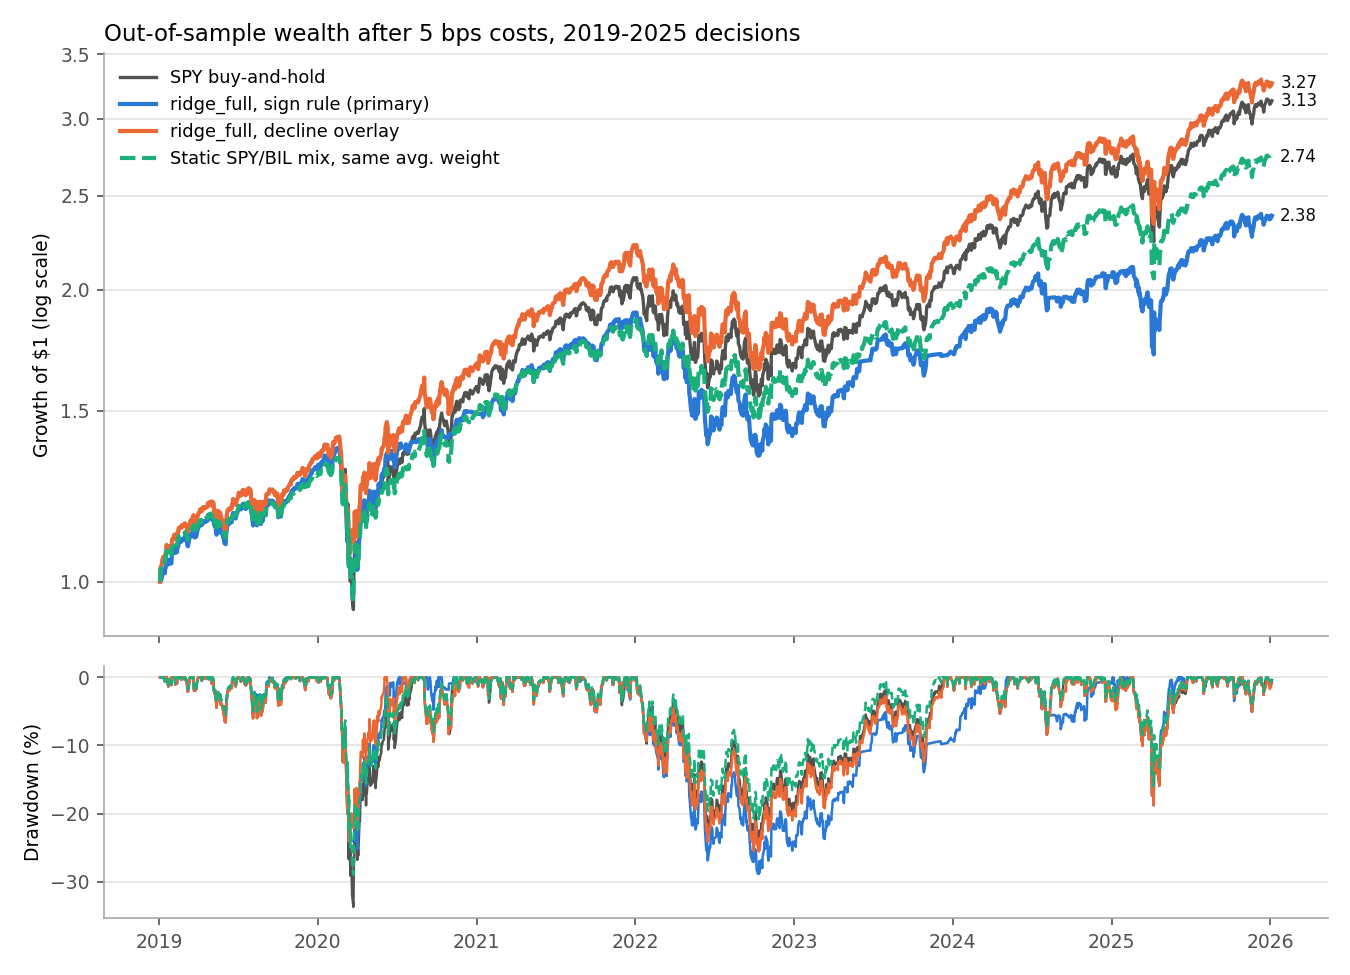

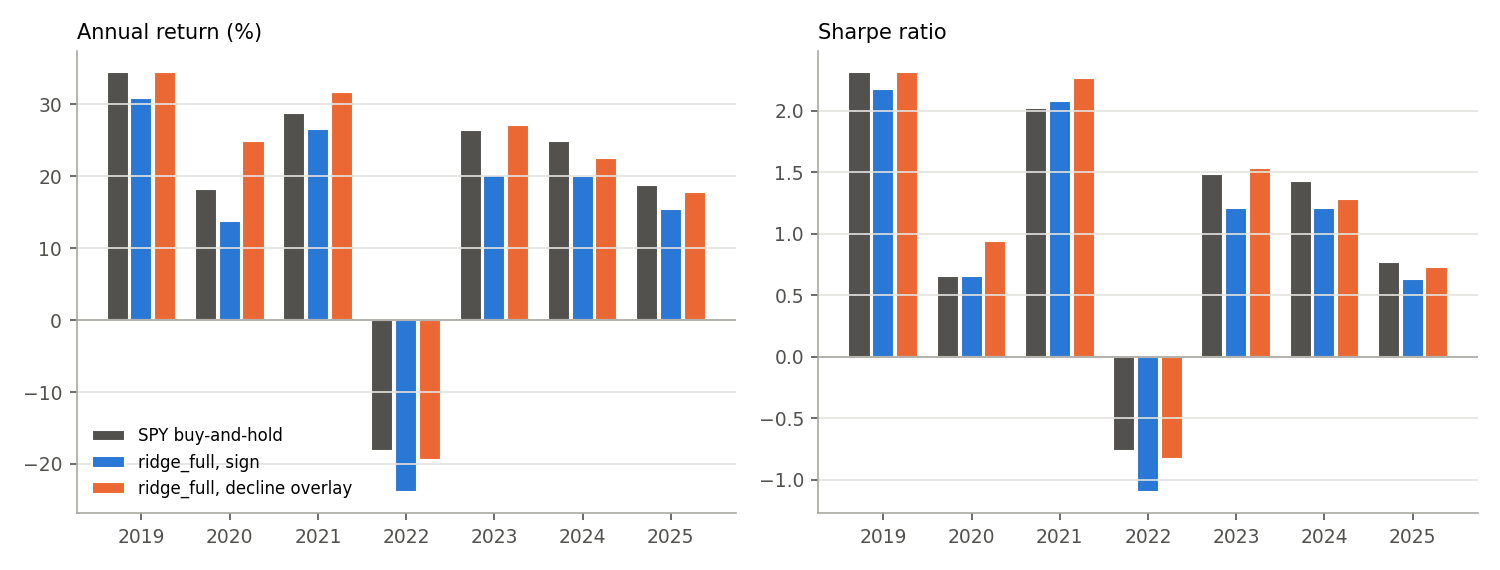

,strategy,model_id,rule,ann_return,ann_vol,sharpe,max_dd,n_days,avg_weight,pct_days_in_spy,turnover_pa,cost_drag_pa,cost_bps
0,historical_mean|sign,historical_mean,sign,0.178,0.197,0.799,-0.337,1761.0,0.999,0.999,0.143,0.000,0.0
1,historical_mean|mv,historical_mean,mv,0.122,0.121,0.807,-0.205,1761.0,0.814,0.999,4.439,0.000,0.0
2,historical_mean|decline_overlay,historical_mean,decline_overlay,0.178,0.197,0.799,-0.337,1761.0,0.999,0.999,0.143,0.000,0.0
3,ridge_base|sign,ridge_base,sign,0.150,0.181,0.722,-0.267,1761.0,0.948,0.948,9.302,0.000,0.0
4,ridge_base|mv,ridge_base,mv,0.124,0.121,0.814,-0.226,1761.0,0.729,0.948,20.634,0.000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,ridge_vix_matched|mv,ridge_vix_matched,mv,0.013,0.120,-0.045,-0.342,1761.0,0.655,0.833,29.622,0.059,20.0
101,ridge_vix_matched|decline_overlay,ridge_vix_matched,decline_overlay,0.170,0.183,0.811,-0.287,1761.0,0.984,0.984,4.436,0.009,20.0
102,spy_bh,spy_bh,NaN,0.177,0.197,0.797,-0.337,1761.0,0.999,0.999,0.143,0.000,20.0
103,bil_bh,bil_bh,NaN,0.026,0.003,NaN,-0.002,1761.0,0.000,0.000,0.000,0.000,20.0


In [13]:
display(Image("reports/backtest/fig_cumulative.png", width=900))
display(Image("reports/backtest/fig_yearly.png", width=900))
display(pd.read_csv("reports/backtest/cost_sensitivity.csv").round(3))

In [14]:
display(pd.read_csv("reports/backtest/event_summary.csv").round(3))
display(Markdown(open("reports/analysis/interaction_tests.md", encoding="utf-8").read()))

,Unnamed: 0,model_id,rule,n_events,n_recovery,n_continuation,w_event_recovery,w_event_continuation,w_event_separation,w_window_separation,excess_vs_spy_recovery,excess_vs_spy_continuation,excess_vs_spy_all
0,historical_mean|sign,historical_mean,sign,53.0,27.0,20.0,1.000,1.000,0.000,0.000,0.000,0.000,0.000
1,historical_mean|mv,historical_mean,mv,53.0,27.0,20.0,0.779,0.888,-0.109,-0.049,-0.010,0.009,-0.002
2,historical_mean|decline_overlay,historical_mean,decline_overlay,53.0,27.0,20.0,1.000,1.000,0.000,0.000,0.000,0.000,0.000
3,ridge_base|sign,ridge_base,sign,53.0,27.0,20.0,0.963,0.950,0.013,-0.074,-0.000,-0.001,-0.000
4,ridge_base|mv,ridge_base,mv,53.0,27.0,20.0,0.790,0.843,-0.053,-0.121,-0.010,0.007,-0.002
5,ridge_base|decline_overlay,ridge_base,decline_overlay,53.0,27.0,20.0,0.963,0.950,0.013,-0.001,0.004,-0.001,0.002
6,ridge_vix_level|sign,ridge_vix_level,sign,53.0,27.0,20.0,0.852,0.900,-0.048,-0.066,-0.006,0.000,-0.003
7,ridge_vix_level|mv,ridge_vix_level,mv,53.0,27.0,20.0,0.711,0.813,-0.101,-0.105,-0.013,0.008,-0.004
8,ridge_vix_level|decline_overlay,ridge_vix_level,decline_overlay,53.0,27.0,20.0,0.852,0.900,-0.048,0.019,-0.000,0.001,-0.001
9,ridge_vix|sign,ridge_vix,sign,53.0,27.0,20.0,0.815,0.900,-0.085,-0.072,-0.007,0.002,-0.003


# Term structure x decline interaction tests

Generated by `python -m src.analysis.interaction_test`. OLS with Newey-West
standard errors (lags = max(h, 5)); two-sided p-values. Specification A:
y on ts_ratio, dec_cond, x_cond_ts. Specification B: y on ts_ratio, dec_mom,
x_mom_ts. b3 is the interaction; b1 + b3 is the ts_ratio effect on a decline
day (meaningful for A). Coefficients are decimal excess returns per unit of
ts_ratio (A) or per unit of dec_mom x (ts_ratio - 1) (B); ts_ratio has a
standard deviation of roughly 0.07, so multiply by 0.1 for a typical move.

| spec            |   horizon | period           |    n |   n_decline_days |      b3 |   t_b3 |   p_b3 |   b1_plus_b3 |   t_b1_plus_b3 |   p_b1_plus_b3 |
|:----------------|----------:|:-----------------|-----:|-----------------:|--------:|-------:|-------:|-------------:|---------------:|---------------:|
| A_decline_x_ts  |         1 | design_2014_2018 | 1256 |              114 |  0.0119 |   0.71 |   0.48 |       0.0115 |           0.71 |           0.48 |
| A_decline_x_ts  |         1 | test_2019_2025   | 1760 |              175 | -0.0379 |  -1.24 |   0.21 |      -0.0294 |          -0.98 |           0.33 |
| A_decline_x_ts  |         1 | full_2014_2025   | 3018 |              289 | -0.0153 |  -0.8  |   0.42 |      -0.0107 |          -0.57 |           0.57 |
| B_momentum_x_ts |         1 | design_2014_2018 | 1256 |              114 | -0.0075 |  -2.08 |   0.04 |      -0.0066 |          -1.1  |           0.27 |
| B_momentum_x_ts |         1 | test_2019_2025   | 1760 |              175 |  0.0046 |   0.73 |   0.46 |       0.0047 |           0.58 |           0.56 |
| B_momentum_x_ts |         1 | full_2014_2025   | 3018 |              289 | -0.0013 |  -0.33 |   0.74 |      -0.0006 |          -0.11 |           0.91 |
| A_decline_x_ts  |        10 | design_2014_2018 | 1247 |              108 |  0.0341 |   0.96 |   0.34 |       0.0512 |           1.6  |           0.11 |
| A_decline_x_ts  |        10 | test_2019_2025   | 1759 |              175 | -0.1481 |  -1.58 |   0.12 |      -0.0988 |          -0.81 |           0.42 |
| A_decline_x_ts  |        10 | full_2014_2025   | 3017 |              289 | -0.0593 |  -0.94 |   0.35 |      -0.0182 |          -0.23 |           0.82 |
| B_momentum_x_ts |        10 | design_2014_2018 | 1247 |              108 | -0.0251 |  -2.09 |   0.04 |      -0.0063 |          -0.21 |           0.84 |
| B_momentum_x_ts |        10 | test_2019_2025   | 1759 |              175 |  0.0559 |   1.8  |   0.07 |       0.0898 |           1.7  |           0.09 |
| B_momentum_x_ts |        10 | full_2014_2025   | 3017 |              289 |  0.0172 |   0.79 |   0.43 |       0.0534 |           1.58 |           0.11 |

Reading the signs. A: b3 > 0 supports the rebound hypothesis (declines that
start in backwardation are followed by higher returns). B: on a sharp decline
dec_mom < 0, and in backwardation ts_ratio - 1 > 0, so x_mom_ts < 0; b3 < 0
therefore supports the hypothesis. In B, b1 + b3 is the ts_ratio effect at
dec_mom = +1 and is not of interest. Twelve regressions are reported; at the
5% level about one false positive is expected by chance.

Secondary, explanatory analysis proposed in the feature-stage README on
2026-11-05 and run unchanged; added after the 2019-2025 forecast and
backtest results were seen. Decline days cluster within episodes, so the
effective sample is the number of episodes, not decline days.

## Answer to the research question

- **Primary strategy** (full ridge, sign rule, 5 bps): 13.2% a year, Sharpe 0.67, against SPY's 17.8% and 0.80. The difference is not significant (p = 0.35).
- **Decline overlay**: Sharpe 0.88, p = 0.45. The edge comes almost entirely from 2020, and the price-only model does just as well.
- **Event weights**: under the primary sign rule, full ridge holds less SPY before recoveries than before continuations; the event analysis does not support useful separation.
- **Interaction test**: leans toward the hypothesis in 2014–2018, flips sign in 2019–2025, and is not significant over the full sample.
- **Recovery classifier**: did not beat the historical prior on primary log loss; no improvement was established. Recovery-versus-rest AUC is 0.56 for price-only and 0.52 with term structure; "rest" includes continuation and unresolved.

**Conclusion:** this retrospective evaluation does not establish that VIX term structure improves recovery prediction or SPY/BIL timing after costs. Prior research exposure and the small number of decline episodes limit the claim.

In [15]:
# Optional: rerun the unit and leakage tests; fail this cell if any test fails.
import subprocess
test_run = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "tests"],
    capture_output=True, text=True,
)
print(test_run.stdout[-600:])
print(test_run.stderr[-1200:])
test_run.check_returncode()



.............................................................................
----------------------------------------------------------------------
Ran 77 tests in 4.768s

OK

